# Binance hourly high-to-open return correlation

This notebook measures the Pearson correlation between hourly high-to-open returns for USDT-quoted pairs whose first observed Binance hourly candle occurred in or before calendar year 2021 UTC. Candidates come from the approved initial 30-pair Binance Spot collection, and the immutable gzip-compressed CSV files are the canonical source.

The return for each candle is defined as:

$$r_t = \frac{high_t - open_t}{open_t}$$

This quantity is the candle's maximum observed appreciation relative to its opening price. It is not a close-to-close holding-period return.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_repository_root(start: Path | None = None) -> Path:
    """Find the repository root from the current working directory."""
    candidate = (start or Path.cwd()).resolve()
    for directory in (candidate, *candidate.parents):
        if (directory / "pyproject.toml").is_file() and (directory / "configs").is_dir():
            return directory
    raise FileNotFoundError("Could not locate the repository root.")


REPOSITORY_ROOT = find_repository_root()
CONFIG_PATH = REPOSITORY_ROOT / "configs/binance_selected_usdt_hourly_collection.json"
RAW_DIRECTORY = REPOSITORY_ROOT / "data/raw/binance/spot/1h"

with CONFIG_PATH.open(encoding="utf-8") as config_file:
    collection_config = json.load(config_file)

CANDIDATE_SYMBOLS = collection_config["symbols"]
BTC_SYMBOL = "BTCUSDT"
FIRST_CANDLE_CUTOFF = pd.Timestamp("2021-12-31T23:59:59.999Z")

print(f"Repository root: {REPOSITORY_ROOT}")
print(f"Candidate symbols: {len(CANDIDATE_SYMBOLS)}")
print(f"Eligibility cutoff for the first observed candle: {FIRST_CANDLE_CUTOFF}")
print(f"Collection interval: {collection_config['interval']}")

Repository root: /Users/marcelapsilverio/projetos/tcc_crypto
Candidate symbols: 30
Eligibility cutoff for the first observed candle: 2021-12-31 23:59:59.999000+00:00
Collection interval: 1h


## Load, validate, and transform the candles

The loader requires exactly one canonical CSV for each configured pair. It checks timestamp uniqueness, chronological order, UTC-hour alignment, positive finite prices, and `high >= open`. It then calculates `(high - open) / open` without altering the raw files.

In [2]:
def load_high_open_return_series(symbol: str) -> tuple[pd.Series, dict[str, object]]:
    """Load one symbol and calculate its validated hourly high-to-open return."""
    matches = sorted((RAW_DIRECTORY / symbol).glob(f"{symbol}_1h_*.csv.gz"))
    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected one canonical CSV for {symbol}, found {len(matches)}: {matches}"
        )

    source_path = matches[0]
    frame = pd.read_csv(
        source_path,
        usecols=["open_time_ms", "open", "high"],
        dtype={"open_time_ms": "int64", "open": "string", "high": "string"},
    )
    timestamps = pd.to_datetime(frame["open_time_ms"], unit="ms", utc=True)
    open_prices = pd.to_numeric(frame["open"], errors="raise").astype("float64")
    high_prices = pd.to_numeric(frame["high"], errors="raise").astype("float64")

    if timestamps.duplicated().any():
        raise ValueError(f"{symbol} contains duplicate opening timestamps.")
    if not timestamps.is_monotonic_increasing:
        raise ValueError(f"{symbol} opening timestamps are not chronological.")
    if not (timestamps.dt.floor("h") == timestamps).all():
        raise ValueError(f"{symbol} contains timestamps outside the UTC hourly grid.")
    if not (np.isfinite(open_prices) & np.isfinite(high_prices)).all():
        raise ValueError(f"{symbol} contains non-finite open or high prices.")
    if not ((open_prices > 0) & (high_prices >= open_prices)).all():
        raise ValueError(f"{symbol} contains invalid open or high prices.")

    returns = (high_prices - open_prices) / open_prices
    if not (np.isfinite(returns) & (returns >= 0)).all():
        raise ValueError(f"{symbol} produced invalid high-to-open returns.")

    series = pd.Series(returns.to_numpy(), index=pd.DatetimeIndex(timestamps), name=symbol)
    summary = {
        "Symbol": symbol,
        "Observations": len(series),
        "First open (UTC)": series.index.min(),
        "Last open (UTC)": series.index.max(),
        "Mean high-to-open return": series.mean(),
        "Maximum high-to-open return": series.max(),
        "Source file": source_path.relative_to(REPOSITORY_ROOT).as_posix(),
    }
    return series, summary


series_by_symbol: list[pd.Series] = []
source_summaries: list[dict[str, object]] = []

for symbol in CANDIDATE_SYMBOLS:
    series, summary = load_high_open_return_series(symbol)
    series_by_symbol.append(series)
    source_summaries.append(summary)

source_summary = pd.DataFrame(source_summaries)
source_summary["Eligible"] = source_summary["First open (UTC)"] <= FIRST_CANDLE_CUTOFF
selected_symbols = source_summary.loc[source_summary["Eligible"], "Symbol"].tolist()
all_returns = pd.concat(series_by_symbol, axis=1, join="outer").sort_index()
hourly_returns = all_returns.loc[:, selected_symbols]

assert BTC_SYMBOL in selected_symbols
assert len(selected_symbols) == 23
assert list(hourly_returns.columns) == selected_symbols
assert hourly_returns.index.is_monotonic_increasing
assert str(hourly_returns.index.tz) == "UTC"

display(
    source_summary.style.format(
        {
            "Mean high-to-open return": "{:.6%}",
            "Maximum high-to-open return": "{:.6%}",
        }
    )
)
print(f"Eligible symbols: {len(selected_symbols)} of {len(CANDIDATE_SYMBOLS)}")
print(", ".join(selected_symbols))
print(f"Aligned UTC grid: {hourly_returns.index.min()} through {hourly_returns.index.max()}")
print(f"Distinct hourly timestamps in the outer-aligned table: {len(hourly_returns):,}")

,Symbol,Observations,First open (UTC),Last open (UTC),Mean high-to-open return,Maximum high-to-open return,Source file,Eligible
0,BTCUSDT,79140,2017-08-17 04:00:00+00:00,2026-09-01 23:00:00+00:00,0.466199%,27.733629%,data/raw/binance/spot/1h/BTCUSDT/BTCUSDT_1h_2017-01-01_2026-09-01.csv.gz,True
1,FLOKIUSDT,29166,2023-05-05 18:00:00+00:00,2026-09-01 23:00:00+00:00,0.878657%,67.182663%,data/raw/binance/spot/1h/FLOKIUSDT/FLOKIUSDT_1h_2017-01-01_2026-09-01.csv.gz,False
2,ETHUSDT,79140,2017-08-17 04:00:00+00:00,2026-09-01 23:00:00+00:00,0.597913%,114.291658%,data/raw/binance/spot/1h/ETHUSDT/ETHUSDT_1h_2017-01-01_2026-09-01.csv.gz,True
3,BONKUSDT,23800,2023-12-15 08:00:00+00:00,2026-09-01 23:00:00+00:00,1.016400%,104.918033%,data/raw/binance/spot/1h/BONKUSDT/BONKUSDT_1h_2017-01-01_2026-09-01.csv.gz,False
4,SOLUSDT,53086,2020-08-11 06:00:00+00:00,2026-09-01 23:00:00+00:00,0.837747%,43.165733%,data/raw/binance/spot/1h/SOLUSDT/SOLUSDT_1h_2017-01-01_2026-09-01.csv.gz,True
5,XRPUSDT,72936,2018-05-04 08:00:00+00:00,2026-09-01 23:00:00+00:00,0.644060%,200.000000%,data/raw/binance/spot/1h/XRPUSDT/XRPUSDT_1h_2017-01-01_2026-09-01.csv.gz,True
6,SHIBUSDT,46566,2021-05-10 11:00:00+00:00,2026-09-01 23:00:00+00:00,0.760486%,254.107649%,data/raw/binance/spot/1h/SHIBUSDT/SHIBUSDT_1h_2017-01-01_2026-09-01.csv.gz,True
7,DOGEUSDT,62728,2019-07-05 12:00:00+00:00,2026-09-01 23:00:00+00:00,0.751050%,69.835912%,data/raw/binance/spot/1h/DOGEUSDT/DOGEUSDT_1h_2017-01-01_2026-09-01.csv.gz,True
8,BNBUSDT,77203,2017-11-06 03:00:00+00:00,2026-09-01 23:00:00+00:00,0.597720%,31.183935%,data/raw/binance/spot/1h/BNBUSDT/BNBUSDT_1h_2017-01-01_2026-09-01.csv.gz,True
9,ADAUSDT,73348,2018-04-17 04:00:00+00:00,2026-09-01 23:00:00+00:00,0.721444%,38.882026%,data/raw/binance/spot/1h/ADAUSDT/ADAUSDT_1h_2017-01-01_2026-09-01.csv.gz,True


Eligible symbols: 23 of 30
BTCUSDT, ETHUSDT, SOLUSDT, XRPUSDT, SHIBUSDT, DOGEUSDT, BNBUSDT, ADAUSDT, LTCUSDT, LINKUSDT, AVAXUSDT, DOTUSDT, TRXUSDT, NEARUSDT, AAVEUSDT, XLMUSDT, ZECUSDT, FILUSDT, BCHUSDT, LUNAUSDT, UNIUSDT, GALAUSDT, FETUSDT
Aligned UTC grid: 2017-08-17 04:00:00+00:00 through 2026-09-01 23:00:00+00:00
Distinct hourly timestamps in the outer-aligned table: 79,140


## Pearson correlation matrix

Each coefficient uses only exact UTC timestamps observed for both assets. Missing candles and pre-listing periods are not interpolated, filled, or synthesized. Pairs with different listing dates therefore use different overlapping periods.

In [3]:
correlation_matrix = hourly_returns.corr(method="pearson", min_periods=2)
availability = hourly_returns.notna().astype("int32")
paired_observation_matrix = availability.T.dot(availability)

if correlation_matrix.isna().any().any():
    missing_pairs = correlation_matrix.isna().stack().loc[lambda values: values].index.tolist()
    raise ValueError(f"Undefined pairwise correlations: {missing_pairs}")

display(
    correlation_matrix.style
    .format("{:.3f}")
    .background_gradient(cmap="coolwarm", vmin=-1, vmax=1)
    .set_caption("Pearson correlation of hourly (high - open) / open returns — pair-specific starts through 2026-09-01 23:00 UTC")
)

,BTCUSDT,ETHUSDT,SOLUSDT,XRPUSDT,SHIBUSDT,DOGEUSDT,BNBUSDT,ADAUSDT,LTCUSDT,LINKUSDT,AVAXUSDT,DOTUSDT,TRXUSDT,NEARUSDT,AAVEUSDT,XLMUSDT,ZECUSDT,FILUSDT,BCHUSDT,LUNAUSDT,UNIUSDT,GALAUSDT,FETUSDT
BTCUSDT,1.000,0.693,0.550,0.399,0.327,0.402,0.618,0.617,0.697,0.550,0.204,0.520,0.486,0.466,0.585,0.501,0.457,0.028,0.595,0.061,0.022,0.310,0.390
ETHUSDT,0.693,1.000,0.580,0.430,0.339,0.402,0.606,0.662,0.716,0.604,0.216,0.555,0.513,0.488,0.671,0.531,0.495,0.029,0.599,0.059,0.028,0.324,0.406
SOLUSDT,0.550,0.580,1.000,0.401,0.296,0.315,0.500,0.519,0.485,0.557,0.206,0.466,0.363,0.449,0.518,0.390,0.353,0.025,0.422,0.060,0.027,0.310,0.366
XRPUSDT,0.399,0.430,0.401,1.000,0.262,0.353,0.345,0.453,0.424,0.411,0.146,0.393,0.423,0.335,0.415,0.651,0.369,0.021,0.452,0.045,0.019,0.255,0.296
SHIBUSDT,0.327,0.339,0.296,0.262,1.000,0.411,0.315,0.315,0.299,0.311,0.293,0.322,0.211,0.252,0.291,0.249,0.212,0.262,0.278,0.033,0.271,0.253,0.213
DOGEUSDT,0.402,0.402,0.315,0.353,0.411,1.000,0.342,0.382,0.380,0.351,0.122,0.307,0.269,0.274,0.334,0.337,0.275,0.014,0.348,0.037,0.013,0.259,0.252
BNBUSDT,0.618,0.606,0.500,0.345,0.315,0.342,1.000,0.541,0.563,0.502,0.196,0.481,0.479,0.433,0.514,0.439,0.413,0.024,0.511,0.059,0.020,0.305,0.381
ADAUSDT,0.617,0.662,0.519,0.453,0.315,0.382,0.541,1.000,0.607,0.535,0.203,0.527,0.476,0.463,0.550,0.622,0.450,0.026,0.531,0.078,0.023,0.314,0.381
LTCUSDT,0.697,0.716,0.485,0.424,0.299,0.380,0.563,0.607,1.000,0.526,0.185,0.495,0.492,0.434,0.534,0.519,0.473,0.027,0.642,0.056,0.022,0.296,0.367
LINKUSDT,0.550,0.604,0.557,0.411,0.311,0.351,0.502,0.535,0.526,1.000,0.213,0.566,0.410,0.493,0.626,0.432,0.399,0.028,0.539,0.062,0.029,0.331,0.361


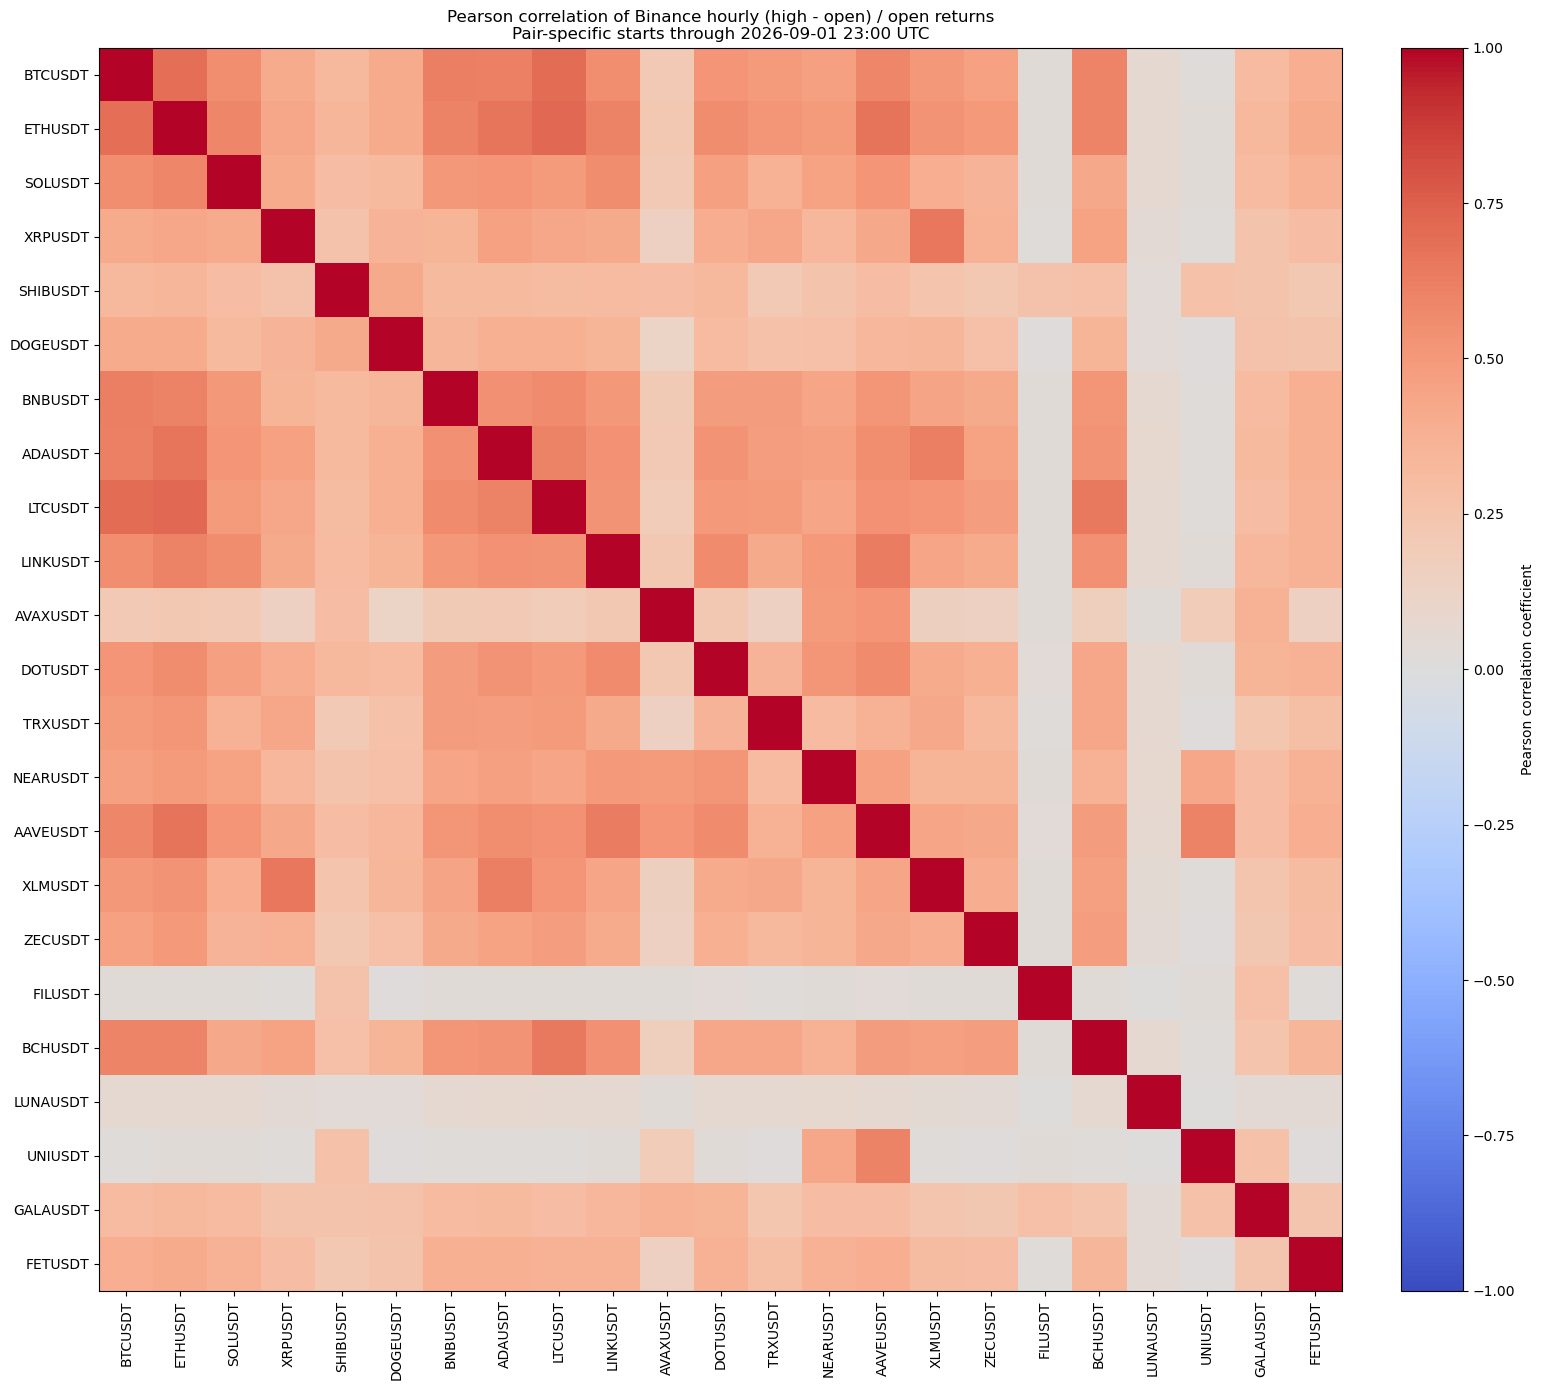

In [4]:
figure, axis = plt.subplots(figsize=(16, 14))
image = axis.imshow(correlation_matrix.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)
axis.set_xticks(range(len(selected_symbols)), labels=selected_symbols, rotation=90)
axis.set_yticks(range(len(selected_symbols)), labels=selected_symbols)
axis.set_title(
    "Pearson correlation of Binance hourly (high - open) / open returns\n"
    "Pair-specific starts through 2026-09-01 23:00 UTC"
)
colorbar = figure.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
colorbar.set_label("Pearson correlation coefficient")
figure.tight_layout()
plt.show()

## Paired-observation counts and relationship with Bitcoin

The count matrix reports the exact sample size supporting each coefficient. The second table isolates and ranks every eligible asset's return correlation with Bitcoin.

In [5]:
display(
    paired_observation_matrix.style
    .format("{:,}")
    .set_caption("Paired hourly observations through 2026-09-01 23:00 UTC used by each coefficient")
)

bitcoin_relationship = (
    pd.DataFrame(
        {
            "Pearson correlation with BTCUSDT": correlation_matrix[BTC_SYMBOL],
            "Paired observations": paired_observation_matrix[BTC_SYMBOL],
        }
    )
    .drop(index=BTC_SYMBOL)
    .sort_values("Pearson correlation with BTCUSDT", ascending=False)
)

display(
    bitcoin_relationship.style
    .format(
        {
            "Pearson correlation with BTCUSDT": "{:.4f}",
            "Paired observations": "{:,}",
        }
    )
    .background_gradient(subset=["Pearson correlation with BTCUSDT"], cmap="coolwarm", vmin=-1, vmax=1)
    .set_caption("Hourly high-to-open return correlation with Bitcoin through 2026-09-01 23:00 UTC, highest to lowest")
)

,BTCUSDT,ETHUSDT,SOLUSDT,XRPUSDT,SHIBUSDT,DOGEUSDT,BNBUSDT,ADAUSDT,LTCUSDT,LINKUSDT,AVAXUSDT,DOTUSDT,TRXUSDT,NEARUSDT,AAVEUSDT,XLMUSDT,ZECUSDT,FILUSDT,BCHUSDT,LUNAUSDT,UNIUSDT,GALAUSDT,FETUSDT
BTCUSDT,"79,140","79,140","53,086","72,936","46,566","62,728","77,203","73,348","76,315","66,794","52,078","52,901","72,021","51,551","51,529","72,287","65,270","51,515","59,238","52,405","52,201","43,551","65,762"
ETHUSDT,"79,140","79,140","53,086","72,936","46,566","62,728","77,203","73,348","76,315","66,794","52,078","52,901","72,021","51,551","51,529","72,287","65,270","51,515","59,238","52,405","52,201","43,551","65,762"
SOLUSDT,"53,086","53,086","53,086","53,086","46,566","53,086","53,086","53,086","53,086","53,086","52,078","52,901","53,086","51,551","51,529","53,086","53,086","51,515","53,086","52,405","52,201","43,551","53,086"
XRPUSDT,"72,936","72,936","53,086","72,936","46,566","62,728","72,936","72,936","72,936","66,794","52,078","52,901","72,021","51,551","51,529","72,287","65,270","51,515","59,238","52,405","52,201","43,551","65,762"
SHIBUSDT,"46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,566","46,129","46,566","43,551","46,566"
DOGEUSDT,"62,728","62,728","53,086","62,728","46,566","62,728","62,728","62,728","62,728","62,728","52,078","52,901","62,728","51,551","51,529","62,728","62,728","51,515","59,238","52,405","52,201","43,551","62,728"
BNBUSDT,"77,203","77,203","53,086","72,936","46,566","62,728","77,203","73,348","76,315","66,794","52,078","52,901","72,021","51,551","51,529","72,287","65,270","51,515","59,238","52,405","52,201","43,551","65,762"
ADAUSDT,"73,348","73,348","53,086","72,936","46,566","62,728","73,348","73,348","73,348","66,794","52,078","52,901","72,021","51,551","51,529","72,287","65,270","51,515","59,238","52,405","52,201","43,551","65,762"
LTCUSDT,"76,315","76,315","53,086","72,936","46,566","62,728","76,315","73,348","76,315","66,794","52,078","52,901","72,021","51,551","51,529","72,287","65,270","51,515","59,238","52,405","52,201","43,551","65,762"
LINKUSDT,"66,794","66,794","53,086","66,794","46,566","62,728","66,794","66,794","66,794","66,794","52,078","52,901","66,794","51,551","51,529","66,794","65,270","51,515","59,238","52,405","52,201","43,551","65,762"


,Pearson correlation with BTCUSDT,Paired observations
LTCUSDT,0.6972,"76,315"
ETHUSDT,0.6934,"79,140"
BNBUSDT,0.6180,"77,203"
ADAUSDT,0.6167,"73,348"
BCHUSDT,0.5951,"59,238"
AAVEUSDT,0.5845,"51,529"
SOLUSDT,0.5505,"53,086"
LINKUSDT,0.5500,"66,794"
DOTUSDT,0.5196,"52,901"
XLMUSDT,0.5012,"72,287"


## Interpretation limits

This analysis measures synchronous linear association between the defined hourly high-to-open return series. Correlation does not establish that Bitcoin causes another asset's return, nor does it demonstrate predictive power.

The candle high is known only after the hour has unfolded. Therefore, `(high - open) / open` cannot be treated as information available at the candle opening and must not be introduced into an earlier decision timestamp. It is also not necessarily realizable without a trading and execution rule. Pearson correlation can be strongly affected by extreme candles, and pair-specific overlap periods expose different assets to different market regimes.